# Text Preprocessing Assignments

## 0. Create a New Environment

In [1]:
import pandas as pd

In [2]:
pd.set_option('display.max_colwidth', None)

## 1. Text Preprocessing with Pandas

1. Read the _childrens_books.csv_ file into a Jupyter Notebook
2. Within the Description column:
* Make all the text lowercase
* Remove all \xa0 characters
* Remove all punctuation

In [3]:
df = pd.read_csv('../Data/childrens_books.csv')

In [4]:
df.head()

,Ranking,Title,Author,Year,Rating,Description
0,1,Where the Wild Things Are,Maurice Sendak,1963,4.25,"Where the Wild Things Are follows Max, a young boy who, after being sent to his room for misbehaving, imagines sailing to an island filled with wild creatures. As their king, Max tames the beasts and eventually returns home to find his supper waiting for him. This iconic book explores themes of imagination, adventure, and the complex emotions of childhood, all captured through Sendak's whimsical illustrations and story."
1,2,The Very Hungry Caterpillar,Eric Carle,1969,4.34,"The Very Hungry Caterpillar tells the story of a caterpillar who eats through a variety of foods before eventually becoming a butterfly. Eric Carle’s use of colorful collage illustrations and rhythmic text has made this book a beloved classic for young readers. The simple, engaging story introduces children to days of the week, counting, and the concept of metamorphosis. It’s a staple in early childhood education."
2,3,The Giving Tree,Shel Silverstein,1964,4.38,"The Giving Tree is a touching and bittersweet story about a tree that gives everything it has to a boy over the course of his life. As the boy grows up, he takes more from the tree, and the tree continues to give, even when it has little left. Silverstein’s minimalist text and illustrations convey deep themes of unconditional love, selflessness, and the passage of time. It has sparked much discussion about relationships and sacrifice."
3,4,Green Eggs and Ham,Dr. Seuss,1960,4.31,"In Green Eggs and Ham, Sam-I-Am tries to convince a reluctant character to try a dish of green eggs and ham, despite his resistance. Through repetition and rhyme, Dr. Seuss’s classic story about being open to new experiences encourages children to be adventurous and try things outside their comfort zone. The playful illustrations and humorous dialogue make it a fun and educational read for young readers."
4,5,Goodnight Moon,Margaret Wise Brown,1947,4.31,"Goodnight Moon is a gentle, rhythmic bedtime story where a little bunny says goodnight to everything in his room, from the moon to the ""quiet old lady whispering hush."" Its repetitive structure and comforting tone make it ideal for young children. The simple illustrations by Clement Hurd complement the soothing nature of the story, making it a beloved classic for sleep-time reading."


In [5]:
def preprocessing_lower_replace (series: pd.Series) -> pd.Series:
    output = series.str.lower()
    output = output.str.replace(r'\[.*?\]', '', regex=True) # remove [...]
    output = output.str.replace(r'[^\w\s]', '', regex=True) # remove punctuation
    return output

In [6]:
df['Description_Clean'] = preprocessing_lower_replace(df['Description'])

In [7]:
df[['Description', 'Description_Clean']].head()

,Description,Description_Clean
0,"Where the Wild Things Are follows Max, a young boy who, after being sent to his room for misbehaving, imagines sailing to an island filled with wild creatures. As their king, Max tames the beasts and eventually returns home to find his supper waiting for him. This iconic book explores themes of imagination, adventure, and the complex emotions of childhood, all captured through Sendak's whimsical illustrations and story.",where the wild things are follows max a young boy who after being sent to his room for misbehaving imagines sailing to an island filled with wild creatures as their king max tames the beasts and eventually returns home to find his supper waiting for him this iconic book explores themes of imagination adventure and the complex emotions of childhood all captured through sendaks whimsical illustrations and story
1,"The Very Hungry Caterpillar tells the story of a caterpillar who eats through a variety of foods before eventually becoming a butterfly. Eric Carle’s use of colorful collage illustrations and rhythmic text has made this book a beloved classic for young readers. The simple, engaging story introduces children to days of the week, counting, and the concept of metamorphosis. It’s a staple in early childhood education.",the very hungry caterpillar tells the story of a caterpillar who eats through a variety of foods before eventually becoming a butterfly eric carles use of colorful collage illustrations and rhythmic text has made this book a beloved classic for young readers the simple engaging story introduces children to days of the week counting and the concept of metamorphosis its a staple in early childhood education
2,"The Giving Tree is a touching and bittersweet story about a tree that gives everything it has to a boy over the course of his life. As the boy grows up, he takes more from the tree, and the tree continues to give, even when it has little left. Silverstein’s minimalist text and illustrations convey deep themes of unconditional love, selflessness, and the passage of time. It has sparked much discussion about relationships and sacrifice.",the giving tree is a touching and bittersweet story about a tree that gives everything it has to a boy over the course of his life as the boy grows up he takes more from the tree and the tree continues to give even when it has little left silversteins minimalist text and illustrations convey deep themes of unconditional love selflessness and the passage of time it has sparked much discussion about relationships and sacrifice
3,"In Green Eggs and Ham, Sam-I-Am tries to convince a reluctant character to try a dish of green eggs and ham, despite his resistance. Through repetition and rhyme, Dr. Seuss’s classic story about being open to new experiences encourages children to be adventurous and try things outside their comfort zone. The playful illustrations and humorous dialogue make it a fun and educational read for young readers.",in green eggs and ham samiam tries to convince a reluctant character to try a dish of green eggs and ham despite his resistance through repetition and rhyme dr seusss classic story about being open to new experiences encourages children to be adventurous and try things outside their comfort zone the playful illustrations and humorous dialogue make it a fun and educational read for young readers
4,"Goodnight Moon is a gentle, rhythmic bedtime story where a little bunny says goodnight to everything in his room, from the moon to the ""quiet old lady whispering hush."" Its repetitive structure and comforting tone make it ideal for young children. The simple illustrations by Clement Hurd complement the soothing nature of the story, making it a beloved classic for sleep-time reading.",goodnight moon is a gentle rhythmic bedtime story where a little bunny says goodnight to everything in his room from the moon to the quiet old lady whispering hush its repetitive structure and comforting tone make it ideal 

## 2. Text Preprocessing with spaCy

In addition to the lowercasing and special character removal from the previous assignment, within the cleaned Description column:
* Tokenize the text
* Lemmatize the text
* Remove stop words

In [8]:
import spacy

In [9]:
nlp = spacy.load('en_core_web_sm')

In [10]:
def nlp_pipeline(text:str):
    doc = nlp(text)
    output = [token.lemma_ for token in doc if not token.is_stop]
    output = ' '.join(output)
    return output

In [11]:
text_clean = df.Description_Clean.apply(nlp_pipeline)

In [13]:
text_clean.head()

0                          wild thing   follow max young boy send room misbehave imago sail island fill wild creature king max tame beast eventually return home find supper wait iconic book explore theme imagination adventure complex emotion childhood capture sendak whimsical illustration story
1        hungry caterpillar   tell story caterpillar eat variety food eventually butterfly eric carles use colorful collage illustration rhythmic text book beloved classic young reader simple engaging story introduce child day week counting concept metamorphosis staple early childhood education
2                                         give tree   touching bittersweet story tree give boy course life boy grow take tree tree continue little left silverstein minimalist text illustration convey deep theme unconditional love selflessness passage time spark discussion relationship sacrifice
3      green egg ham samiam try convince reluctant character try dish green egg ham despite resistance repetitio

## 3. Count Vectorizer

1. Vectorize the cleaned and normalized text using Count Vectorizer with the default parameters
2. Modify the Count Vectorizer parameters to reduce the number of columns:
* Remove stop words
* Set a minimum document frequency of 10%
3. Use the updated Count Vectorizer to identify the:
* Top 10 most common terms
* Top 10 least common terms that appear in at least 10% of the documents
4. Create a horizontal bar chart of the top 10 most common terms

In [14]:
from sklearn.feature_extraction.text import CountVectorizer

In [15]:
cv = CountVectorizer()

In [16]:
dtm = cv.fit_transform(text_clean)

In [17]:
pd.DataFrame(dtm.toarray(), columns=cv.get_feature_names_out())

,19th,207,30story,aa,aaron,ability,aboard,absurd,absurdity,acceptance,...,worldbuilde,wrap,wrinkle,write,writing,wrong,year,young,zany,zone
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,1
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
96,0,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
97,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0
98,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0


In [29]:
cv2 = CountVectorizer(stop_words='english', ngram_range=(1, 2), min_df=.1)

In [30]:
dtm2 = cv2.fit_transform(text_clean)

In [31]:
dtm_df2 = pd.DataFrame(dtm2.toarray(), columns=cv2.get_feature_names_out())

In [32]:
dtm_df2

,adventure,beloved,book,boy,character,charming,child,classic,courage,early,...,tell story,text,theme,timeless,way,whimsical,world,young,young child,young reader
0,1,0,1,1,0,0,0,0,0,0,...,0,0,1,0,0,1,0,1,0,0
1,0,1,1,0,0,0,1,1,0,1,...,1,1,0,0,0,0,0,1,0,1
2,0,0,0,2,0,0,0,0,0,0,...,0,1,1,0,0,0,0,0,0,0
3,0,0,0,0,1,0,1,1,0,0,...,0,0,0,0,0,0,0,1,0,1
4,0,1,0,0,0,0,1,1,0,0,...,0,0,0,0,0,0,0,1,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,0,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
96,0,0,1,0,0,0,1,0,0,0,...,0,0,0,1,0,1,0,0,0,0
97,0,0,1,0,0,0,0,0,0,0,...,0,0,1,0,0,0,1,0,0,0
98,1,0,1,0,0,0,0,0,1,0,...,0,0,1,0,0,0,0,0,0,0


In [33]:
frequency = dtm_df2.sum().sort_values()

In [34]:
frequency

embark            10
favorite          10
early             10
joy               10
perfect           10
importance        11
girl              11
imagination       11
magical           11
imaginative       11
courage           12
fun               12
novel             12
message           12
gentle            12
charming          12
text              12
rhyme             12
narrative         13
whimsical         13
introduce         13
timeless          14
way               15
boy               15
family            15
world             16
life              17
character         17
engage            17
explore theme     17
tale              18
humor             19
teach             19
young child       19
playful           19
beloved           19
humorous          20
learn             20
lesson            20
little            20
read              21
young reader      21
simple            22
love              23
friendship        24
tell story        25
make              26
series       

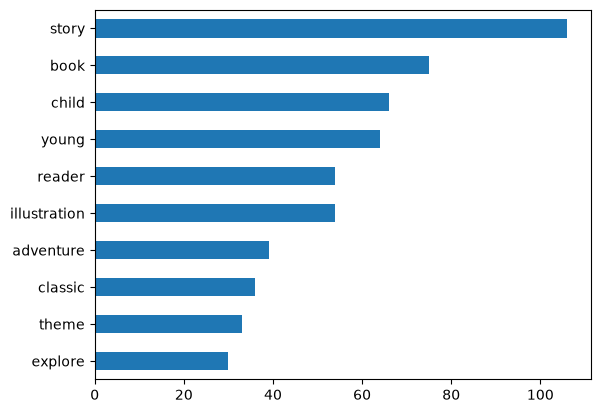

In [35]:
frequency[-10:].plot(kind='barh');

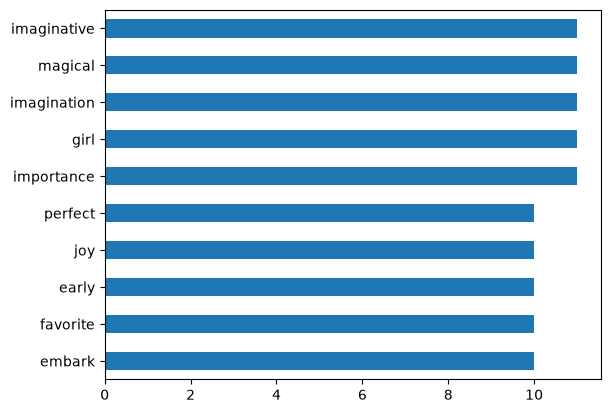

In [40]:
frequency[:10].plot(kind='barh');

## 4. TF-IDF Vectorizer

1. Vectorize the cleaned and normalized text using TF-IDF Vectorizer with the default parameters
2. Modify the TF-IDF Vectorizer parameters to reduce the number of columns:
* Remove stop words
* Set a minimum document frequency of 10%
* Set a maximum document frequency of 50%
3. Using the updated TF-IDF Vectorizer, create a  horizontal bar chart of the top 10 most highly weighted terms
4. Compare the Count Vectorizer bar chart from the previous assignment with the TF-IDF Vectorizer bar chart and note the differences in the top term lists

In [41]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [42]:
tv = TfidfVectorizer()

In [44]:
tfidf = tv.fit_transform(text_clean)
tfidf_df = pd.DataFrame(tfidf.toarray(), columns=tv.get_feature_names_out())

In [45]:
tfidf_df

,19th,207,30story,aa,aaron,ability,aboard,absurd,absurdity,acceptance,...,worldbuilde,wrap,wrinkle,write,writing,wrong,year,young,zany,zone
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00000,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.059161,0.0,0.000000
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00000,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.064643,0.0,0.000000
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00000,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.000000
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00000,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.054494,0.0,0.172525
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00000,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.059258,0.0,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00000,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.000000
96,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.15893,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.000000
97,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00000,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.130180,0.000000,0.0,0.000000
98,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00000,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.132833,0.000000,0.0,0.000000


In [46]:
tv = TfidfVectorizer(stop_words='english', ngram_range=(1, 2), min_df=.1, max_df=.5)
tfidf = tv.fit_transform(text_clean)
tfidf_df = pd.DataFrame(tfidf.toarray(), columns=tv.get_feature_names_out())

In [47]:
tfidf_df

,adventure,beloved,boy,character,charming,classic,courage,early,embark,engage,...,tell,tell story,text,theme,timeless,way,whimsical,world,young child,young reader
0,0.284247,0.000000,0.404995,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.0,...,0.00000,0.000000,0.000000,0.288310,0.000000,0.000000,0.404995,0.000000,0.000000,0.000000
1,0.000000,0.323152,0.000000,0.000000,0.0,0.247257,0.000000,0.396907,0.0,0.0,...,0.27313,0.290784,0.376297,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.311394
2,0.000000,0.000000,0.695432,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.0,...,0.00000,0.000000,0.356375,0.247534,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
3,0.000000,0.000000,0.000000,0.357801,0.0,0.257775,0.000000,0.000000,0.0,0.0,...,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.324640
4,0.000000,0.385781,0.000000,0.000000,0.0,0.295177,0.000000,0.000000,0.0,0.0,...,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.385781,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,0.000000,0.000000,0.000000,0.000000,0.0,0.607668,0.000000,0.000000,0.0,0.0,...,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
96,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.0,...,0.00000,0.000000,0.000000,0.000000,0.463859,0.000000,0.474868,0.000000,0.000000,0.000000
97,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.0,...,0.00000,0.000000,0.000000,0.309008,0.000000,0.000000,0.000000,0.424007,0.000000,0.000000
98,0.310365,0.000000,0.000000,0.000000,0.0,0.000000,0.465112,0.000000,0.0,0.0,...,0.00000,0.000000,0.000000,0.314801,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


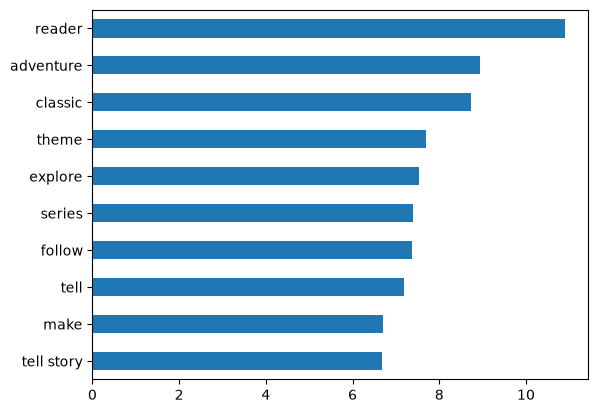

In [52]:
tfidf_df.sum().sort_values()[-10:].plot(kind='barh');